# 04｜LSTM：Dropout × Early Stopping 2×2 對照

固定架構：Embedding(12,000,100) → LSTM(64) → 可選 Dropout(0.3) → Dense(1,sigmoid)。

| Run | Dropout | Early Stopping | 是否重新訓練 |
|---|---|---|---|
| DL-02（Gate B 基準） | 無 | 無 | 不重訓 |
| DL-04 | 有，0.3 | 無 | 新增 |
| DL-05 | 無 | 有，patience=3 | 新增 |
| DL-06 | 有，0.3 | 有，patience=3 | 新增 |

EarlyStopping 僅監看 Validation 的 val_loss，restore_best_weights=True。Epoch 上限 10；使用同一份 v1.1 Train / Validation；官方 Test 不參與。


In [1]:
from pathlib import Path
import json,sys
ROOT=Path('/workspace/imdb_matrix_experiment/variants/dedup_v1_1')
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import yaml,numpy as np,pandas as pd
from IPython.display import display,Image
from src.common import file_hash
from src.evaluation import phase1_settings
base,base_sha,manifest=phase1_settings()
p=ROOT/'config/phase2_conditions.yaml'
cfg=yaml.safe_load(p.read_text(encoding='utf8'))
assert cfg['phase1_config_sha256']==base_sha
assert cfg['split_assignments_sha256']==manifest['split_assignments_sha256']
assert cfg['test_policy']=='do_not_evaluate_until_gate_e'
print('Variant:',manifest['version'],'Gate A SHA:',manifest['split_assignments_sha256'])
print('Phase 2 SHA:',file_hash(p))
print('Test policy:',cfg['test_policy'])
from src.evaluation import subset_data
train,val=subset_data()
assert len(train)==19823 and len(val)==4956
print('Shared:',cfg['shared'])
print('Regularization:',cfg['regularization'])


Variant: dedup_v1.1 Gate A SHA: 9e25b0d714d1fb555c8c8a58fa6858c392ec60ecfba554b923553626154174e9
Phase 2 SHA: a13de8d435a85d888ae9565ed462c35630c88b61f0a6a7692e187e967ae436b4
Test policy: do_not_evaluate_until_gate_e
Shared: {'embedding_dim': 100, 'hidden_units': 64, 'vocab_size': 12000, 'sequence_length': 160, 'mask_zero': True, 'batch_size': 128, 'epochs': 10, 'optimizer': 'Adam', 'learning_rate': 0.001, 'loss': 'binary_crossentropy', 'threshold': 0.5, 'train_shuffle': True, 'seed': 42}
Regularization: {'baseline': 'DL-02-s42', 'units': 64, 'dropout': 0.3, 'monitor': 'val_loss', 'patience': 3, 'min_delta': 0.0, 'restore_best_weights': True, 'conditions': {'DL-04': {'dropout': True, 'early_stopping': False}, 'DL-05': {'dropout': False, 'early_stopping': True}, 'DL-06': {'dropout': True, 'early_stopping': True}}}


## 1. 建模邏輯與控制變因
三個新增條件都只有單層 LSTM；Early Stopping 是訓練 callback，Dropout 是訓練時的隨機正則化層，而非另一種 RNN 架構。

In [2]:
import tensorflow as tf
from src.phase2_factory import build_phase2
assert tf.config.list_physical_devices('GPU')
for run in ('DL-04','DL-05','DL-06'):
    tf.keras.utils.set_random_seed(42)
    model=build_phase2(run,cfg['shared'],cfg['regularization']['dropout'])
    print(run,'params:',model.count_params(),'layers:',
          [layer.__class__.__name__ for layer in model.layers])
    del model
    tf.keras.backend.clear_session()


I0000 00:00:1793793656.289864   23396 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4599 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060, pci bus id: 0000:02:00.0, compute capability: 7.5


DL-04 params: 1242305 layers: ['InputLayer', 'Embedding', 'LSTM', 'Dropout', 'Dense']
DL-05 params: 1242305 layers: ['InputLayer', 'Embedding', 'LSTM', 'Dense']
DL-06 params: 1242305 layers: ['InputLayer', 'Embedding', 'LSTM', 'Dropout', 'Dense']


## 2. 執行三個新增條件
完整記錄訓練 epoch、最佳 val_loss epoch 與還原權重後的 Validation 評估結果。若已有完成 Run，僅載入，不覆蓋 Gate B 的 DL-02。

In [3]:
import subprocess
needed=['DL-04-s42','DL-05-s42','DL-06-s42']
runs=pd.read_csv(ROOT/'results/runs.csv')
assert (runs.run_id=='DL-02-s42').sum()==1,'Missing Phase 1 LSTM baseline'
missing=[x[:-4] for x in needed if x not in set(runs.run_id)]
print('New runs needed:',missing)
if missing:
    subprocess.run([sys.executable,'-B','-m','src.phase2_train','--runs',*missing],cwd=ROOT,check=True)
print('Complete.')


New runs needed: []
Complete.


## 3. 2×2 Validation 對照表
這個矩陣比較正則化與提早停止的個別及交互作用。EarlyStopping 的正式分數取還原權重後模型，而不是最後訓練 epoch 的歷史列。

In [4]:
ids=['DL-02-s42']+needed
rows=pd.read_csv(ROOT/'results/runs.csv')
sel=rows[rows.run_id.isin(ids)].set_index('run_id').loc[ids].reset_index()
assert len(sel)==4
output=sel[['run_id','val_accuracy','val_precision','val_recall','val_f1','val_loss',
            'epochs_completed','trainable_params','train_time_sec']]
display(output.round(4))
for rid in needed:
    md=json.loads((ROOT/f'results/{rid}_training_metadata.json').read_text())
    print(rid,'condition=',md['condition'],
          'trained epochs=',md['epochs_completed'],
          'best val_loss epoch=',md['best_val_loss_epoch'],
          'restored weights=',md['weights_restored'],
          'final val_loss=',round(md['final_model_val_loss'],5))


,run_id,val_accuracy,val_precision,val_recall,val_f1,val_loss,epochs_completed,trainable_params,train_time_sec
0,DL-02-s42,0.8247,0.8525,0.7871,0.8185,0.7924,10.0,1242305.0,13.6681
1,DL-04-s42,0.7962,0.7908,0.8080,0.7993,0.7951,10.0,1242305.0,24.6234
2,DL-05-s42,0.8454,0.8503,0.8401,0.8452,0.3724,4.0,1242305.0,9.9430
3,DL-06-s42,0.8366,0.8346,0.8413,0.8379,0.4065,5.0,1242305.0,12.3065


DL-04-s42 condition= {'dropout': True, 'early_stopping': False} trained epochs= 10 best val_loss epoch= 3 restored weights= False final val_loss= 0.79506
DL-05-s42 condition= {'dropout': False, 'early_stopping': True} trained epochs= 4 best val_loss epoch= 1 restored weights= True final val_loss= 0.37241
DL-06-s42 condition= {'dropout': True, 'early_stopping': True} trained epochs= 5 best val_loss epoch= 2 restored weights= True final val_loss= 0.40649


## 4. 學習曲線與混淆矩陣
觀察 Validation Loss 在無早停時是否上升。EarlyStopping 可能只訓練少於 10 epochs；不能隱藏實際 Epoch 差異。

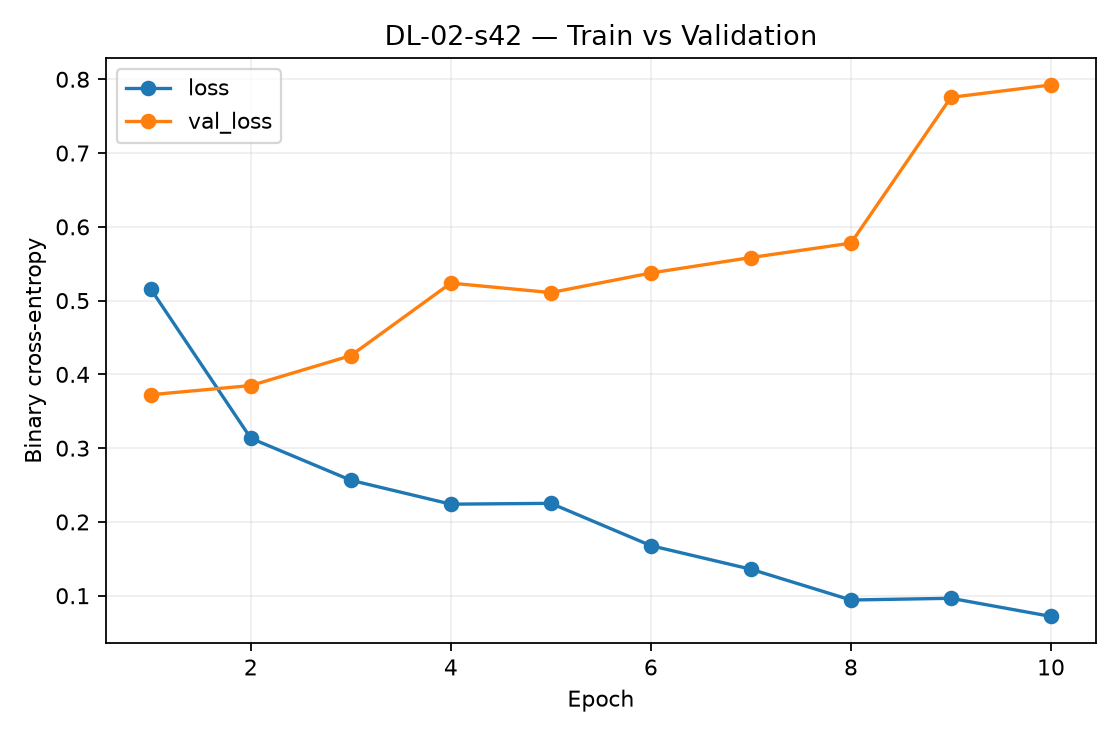

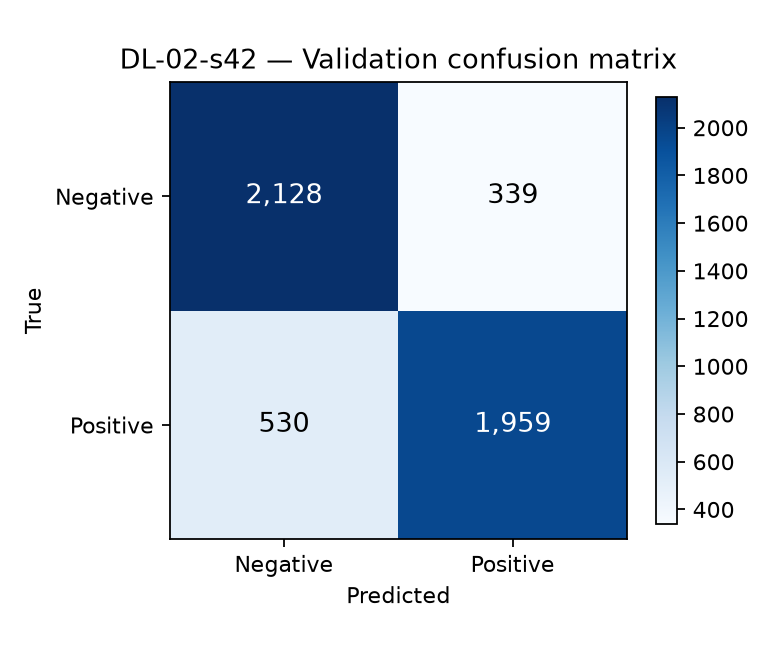

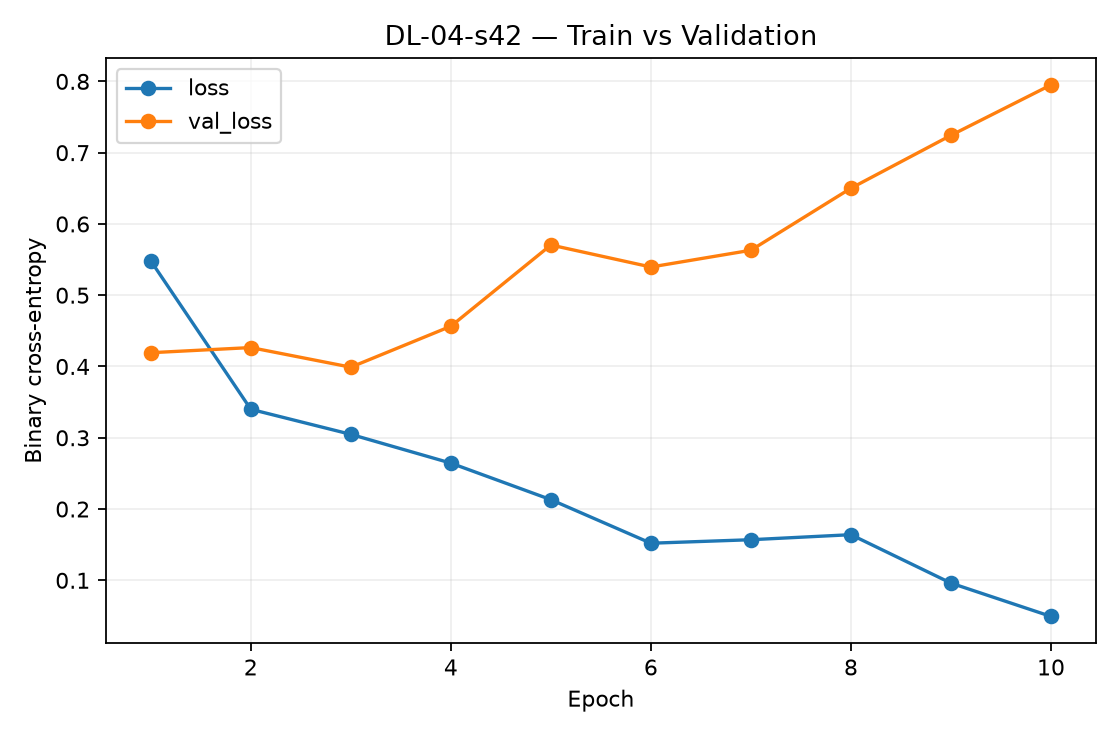

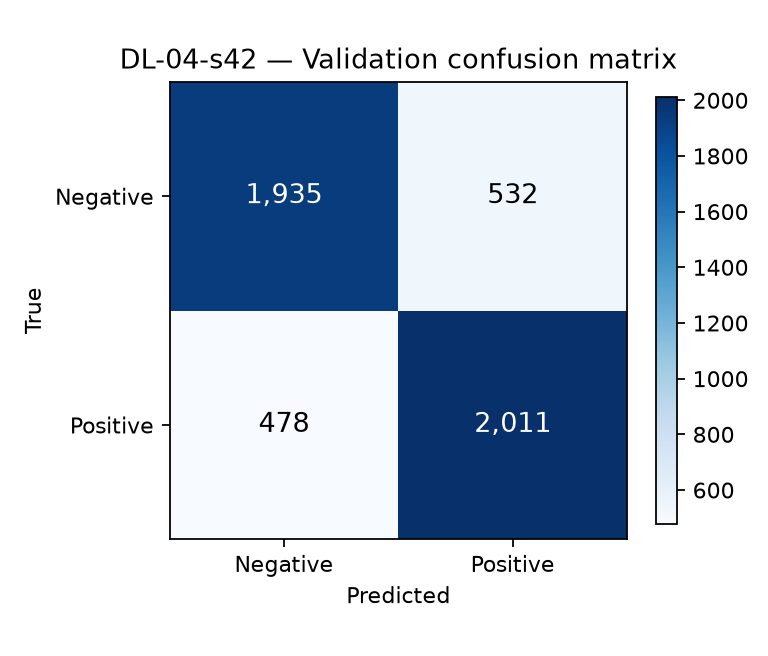

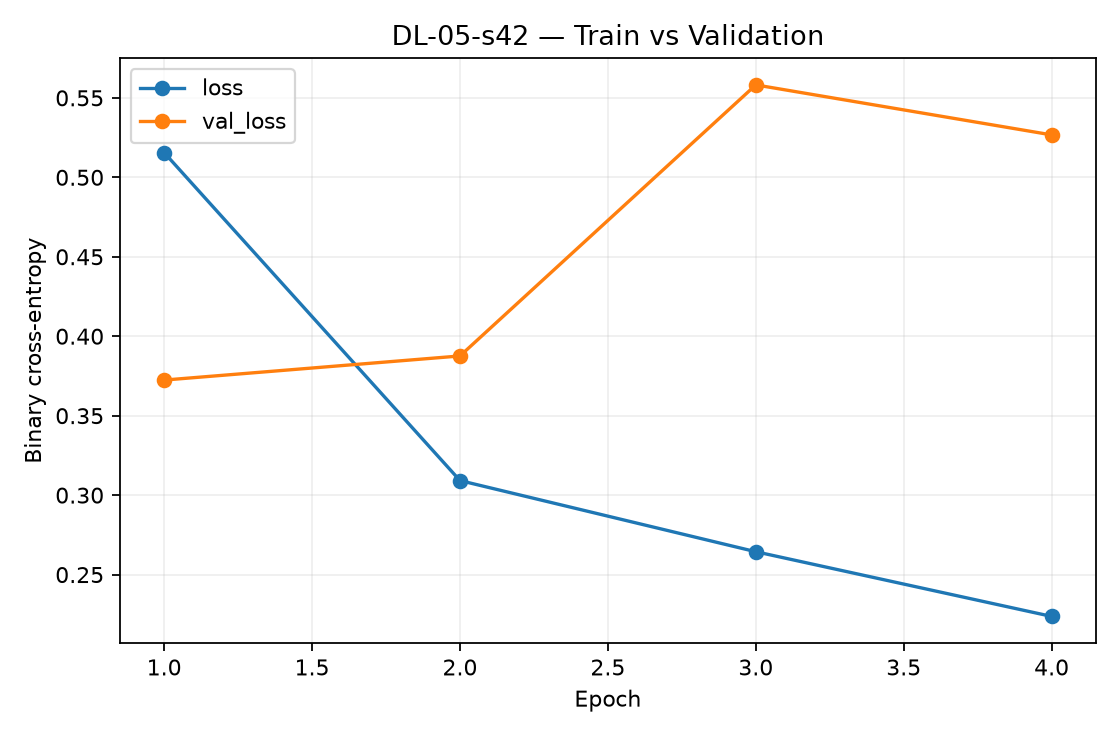

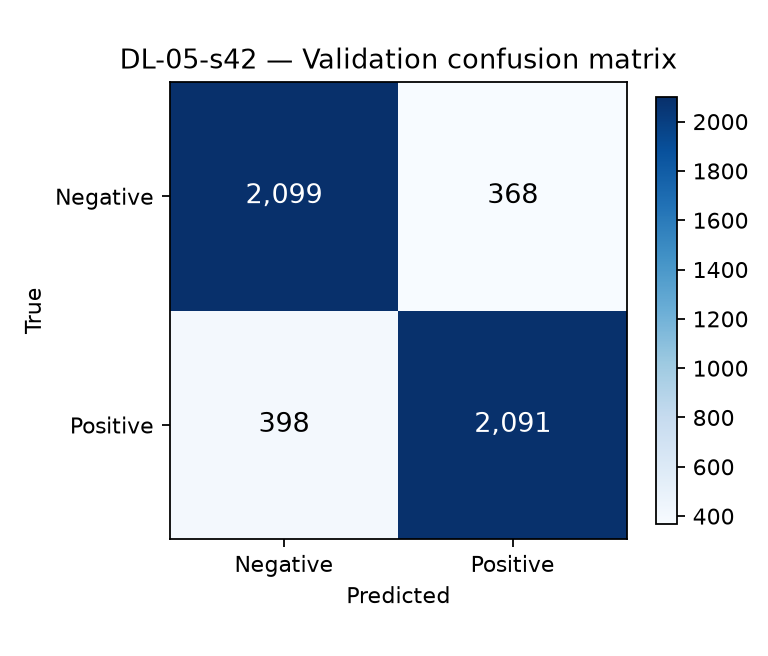

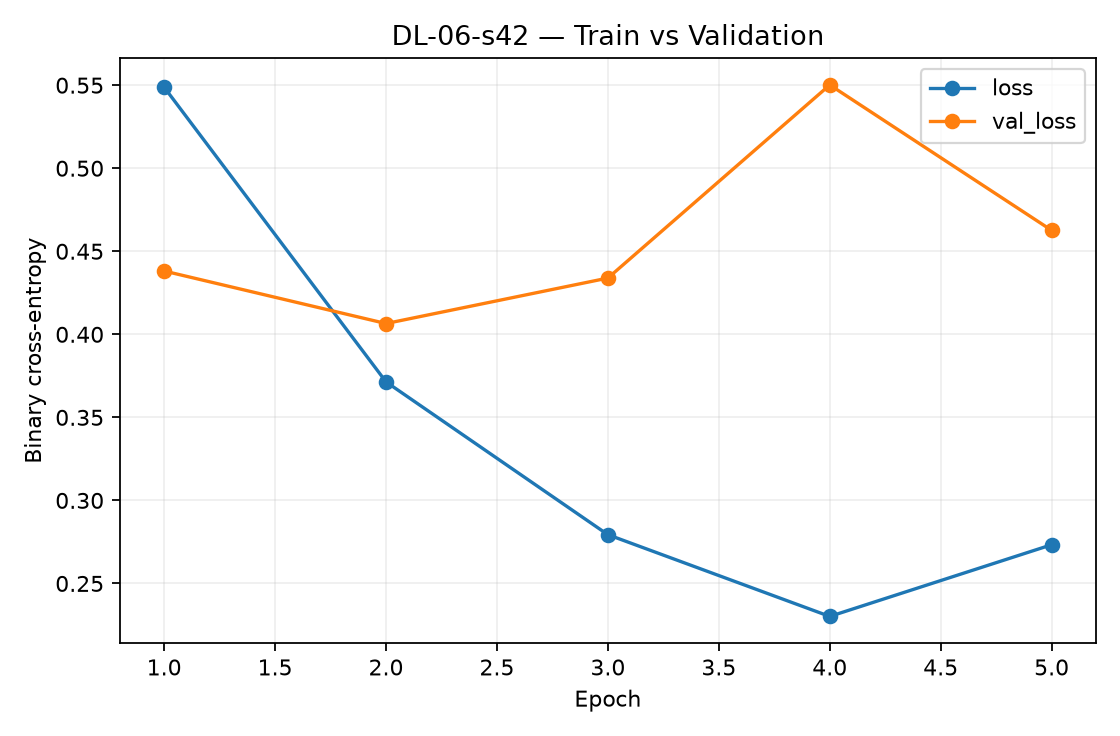

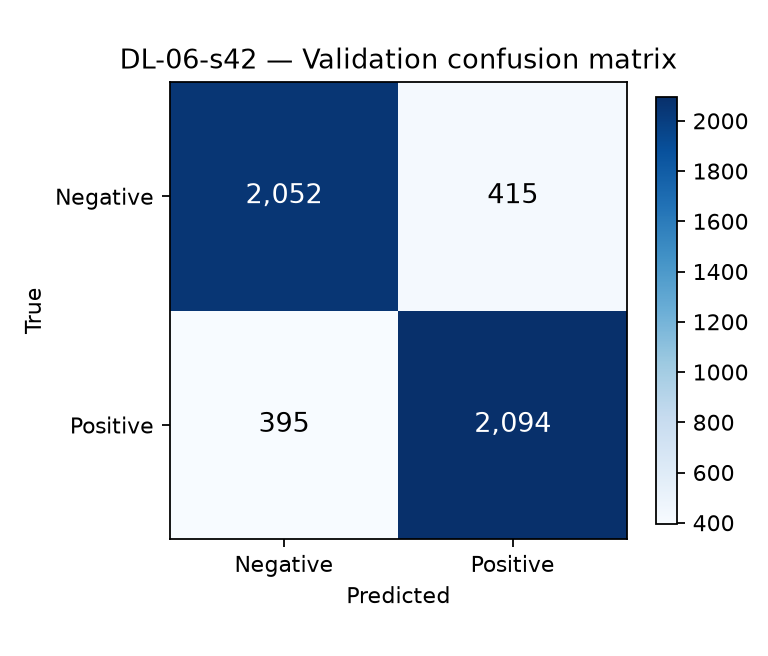

In [5]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(7,3.4))
ax.bar(sel.run_id,sel.val_f1)
ax.set(ylim=(0,1),ylabel='Validation F1',title='LSTM Dropout x EarlyStopping (dedup_v1.1)')
ax.grid(axis='y',alpha=.2)
plt.show()
for rid in ids:
    display(Image(filename=str(ROOT/f'results/figures/{rid}_learning_curve.png'),width=490))
    display(Image(filename=str(ROOT/f'results/figures/{rid}_val_confusion_matrix.png'),width=330))


## 小結
所有 2×2 分數都是 Validation 成績，單次 seed=42；此階段不得用 Test 反覆調整正則化設定。DL-02 直接沿用 Gate B 原模型，不重複訓練。